# A predictor for a microscope we do not know, rehearsed offline through PyJEM

The model of `neoarm_model.ipynb` has about 90 numbers. On the real NEOARM none of them is known well. This
notebook rehearses, without the microscope, the whole way from "unknown microscope" to "a model that predicts
where the beam lands":

1. **A hidden microscope** behind PyJEM's own calls (TemGym's simulated microscope). It is a NEOARM-like column with
   numbers the rest of the notebook never reads.
2. **A recording**, made with plain PyJEM calls only, so the same cell runs on the real microscope: at each of 21
   console rows, size and centre the beam, kick every deflector, wobble every projection lens.
3. **A fit**: the model's numbers are changed (JAX gradients, on the GPU) until the model reproduces the frames.
4. **A test** on what the fit never saw: seven console rows kept back, one spot kept back, and moves of several
   controls at once.
5. **Steering**: the fitted model is turned round to put the beam where we ask.
6. **Which frames are needed**, and what one camera cannot pin down (lens positions, and L).

In [1]:
import json
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jax.flatten_util import ravel_pytree

jax.config.update("jax_enable_x64", True)

from temgym_core.components import Deflector, ElectromagneticLens, Lens, Plane, Scanner
from temgym_core.components.lenses import compute_Rc_from_voltage
from temgym_core.constants import effective_accelerating_potential
from temgym_core.pyjem_simulator import CameraModel, LensHysteresis, SimulatedMicroscope
from temgym_core.ray import Ray
from temgym_core.run import run_to_end

HERE = Path.cwd()                                   # examples/microscope_inversion
OUT = HERE / "results/predictor_offline"
VOLTAGE = 200e3
LENSES = ("CL1", "CL3", "CM", "IL1", "IL2", "IL3", "PL1")
DEFLECTORS = ("CLA1", "CLA2", "IS1", "IS2", "PLA")
MIDDLE_DAC = (32768.0, 32768.0, 32768.0, 31593.0, 43363.0, 31047.0, 61029.5)   # φ is measured from here: the middle
                                                    # of the DAC values the console table gives each projection lens
RC = float(compute_Rc_from_voltage(VOLTAGE))        # radians of rotation per ampere-turn (TemGym)
V_STAR = float(effective_accelerating_potential(VOLTAGE))
print("JAX runs on:", jax.devices())

JAX runs on: [CudaDevice(id=0)]


**The model**: the same two functions as in `neoarm_model.ipynb`, unchanged.

In [2]:
def column(p, dac):
    """The NEOARM as TemGym components, from below the source to the camera, for the console's values `dac`."""
    lens = {}
    for i, name in enumerate(LENSES):
        x = (dac[name] - MIDDLE_DAC[i]) / 20000
        phi = jnp.exp(p["phi_a"][i] * x + p["phi_b"][i] * x * x)
        lens[name] = ElectromagneticLens(
            z=p["lens_z"][i], turns=p["theta_per_dac"][i] / RC, current=dac[name],
            Gc=V_STAR * RC**2 * phi / p["lens_w"][i], Tc=p["lens_body"][i] * RC,
            x0=p["lens_xy"][i, 0], y0=p["lens_xy"][i, 1])
    deflector = {}
    for i, name in enumerate(DEFLECTORS):
        kick = p["deflector_kick"][i] @ (dac[name] - 32768.0)
        deflector[name] = Deflector(z=p["deflector_z"][i], def_x=kick[0], def_y=kick[1])
    top, bottom = p["corrector"]
    relay, f = (bottom - top) / 4, p["objective_f"]
    return [
        lens["CL1"], lens["CL3"], deflector["CLA1"], deflector["CLA2"],
        Lens(z=top + relay, focal_length=relay), Lens(z=bottom - relay, focal_length=relay),       # the corrector
        lens["CM"], Lens(z=-f, focal_length=f),                                                    # objective, before
        Plane(z=0.0),                                                                              # the specimen
        Lens(z=p["objective_z"], focal_length=f),                                                  # objective, after
        deflector["IS1"], deflector["IS2"], lens["IL1"], lens["IL2"], lens["IL3"], deflector["PLA"], lens["PL1"],
        Plane(z=p["camera_z"]),
    ]


def beam_on_camera(p, dac):
    """Where the beam lands (x, y: pixels from the frame's middle) and its size (rms along one axis, pixels)."""
    s = p["source"]
    rays = Ray(x=s[0] + jnp.array([0.0, 1.0, 0.0]) * p["source_size"], y=s[1] + jnp.zeros(3),
               dx=s[2] + jnp.array([0.0, 0.0, 1.0]) * p["source_angle"], dy=s[3] + jnp.zeros(3),
               z=p["source_z"] + jnp.zeros(3), pathlength=jnp.zeros(3), voltage=jnp.full(3, VOLTAGE))
    out = run_to_end(rays, column(p, dac))
    xy = jnp.stack([out.x, out.y], axis=1) * p["pixels_per_length"]
    size = jnp.sqrt(jnp.sum((xy[1:] - xy[0]) ** 2) + p["camera_blur"] ** 2)
    return jnp.r_[xy[0] + p["camera_centre"], size]


tables = json.loads((HERE / "recordings/2026-11-17/console_tables.json").read_text())
family = json.loads((HERE / "results/neoarm_family.json").read_text())["members"]
best_guess = {key: np.array(value) for key, value in json.loads((HERE / "results/neoarm_model.json").read_text()).items()}
best_guess["lens_w"][:2] = [0.0557, 0.02198]       # the designed condenser, not the one fitted to the real parallel-beam
# spots in neoarm_model.ipynb: with that one the beam is sized near the condenser's focus and this fit stalls at about
# 5 px on unseen rows (2026-11-18), not yet understood.

## 1. The hidden microscope

We cannot test on the real NEOARM here, so we make one we pretend not to know. It should be as far from our best
guess as the real one might be:

* its projection lenses and objective are **another member of the family**: a different column that follows the
  real console's lens table just as well, with lenses centimetres away from the best guess and different strengths;
* its condenser lenses are a centimetre from the drawing and 8 % stronger or weaker;
* every lens sits a few micrometres off the axis; every deflector has its own strength, direction and skew; the
  source is off the axis and tilted; the camera's middle is off the axis;
* it is in **metres, with its own L** (0.70 m, not the drawing's 0.719): the model works in units of L and never
  learns this number;
* its lenses have hysteresis, its camera has noise and blur.

The console is the real one: the MAG and DIFF lens tables and the spot table read from the NEOARM on 2026-11-17.
**Nothing below this cell reads `hidden`**, except to score the fit at the end.

In [3]:
HIDDEN_MEMBER, SEED, L_HIDDEN = 4, 5, 0.70
rng = np.random.default_rng(SEED)
member = family[HIDDEN_MEMBER]
hidden = {key: value.copy() for key, value in best_guess.items()}
for key in ("lens_z", "lens_w", "lens_body", "phi_a", "phi_b"):
    hidden[key][3:] = member[key]
hidden["objective_f"], hidden["objective_z"] = np.array(member["objective_f"]), np.array(member["objective_z"])
hidden["lens_z"][:3] += rng.normal(0, 0.01, 3)
hidden["lens_w"][:3] *= np.exp(rng.normal(0, 0.08, 3))
hidden["lens_xy"] = rng.normal(0, 1e-5, (7, 2))
hidden["deflector_z"][:4] += rng.normal(0, 0.008, 4)
hidden["deflector_z"][4] = hidden["lens_z"][6]
for i in range(5):
    angle = rng.uniform(0, 2 * np.pi)
    turn = np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    hidden["deflector_kick"][i] = np.exp(rng.normal(0, 0.3)) * hidden["deflector_kick"][i] @ turn @ (np.eye(2) + rng.normal(0, 0.05, (2, 2)))
hidden["source"] = np.r_[rng.normal(0, 1e-6, 2), rng.normal(0, 5e-6, 2)]
hidden["source_size"] = hidden["source_size"] * np.exp(rng.normal(0, 0.3))
hidden["source_angle"] = hidden["source_angle"] * np.exp(rng.normal(0, 0.3))
hidden["camera_centre"] = rng.normal(0, 8, 2)
for key in ("lens_z", "lens_w", "lens_body", "lens_xy", "deflector_z", "corrector", "objective_f", "objective_z", "source_z",
            "source_size", "camera_z"):                                    # lengths: from units of L to metres
    hidden[key] = hidden[key] * L_HIDDEN
hidden["source"][:2] *= L_HIDDEN
hidden["pixels_per_length"] = np.array(1 / (4 * 62.6e-6))
hidden = {key: jnp.asarray(value) for key, value in hidden.items()}


def hidden_column(console, voltage):
    """What the simulated microscope asks for: the hidden column at the console's values, and the beam at the source."""
    dac = {name: jnp.asarray(console[name], float) for name in LENSES + DEFLECTORS}
    middle = hidden["camera_centre"] / hidden["pixels_per_length"]
    parts = column(hidden, dac) + [Scanner(z=hidden["camera_z"], scan_pos_x=middle[0], scan_pos_y=middle[1])]
    spread = np.diag([float(hidden["source_size"]) ** 2] * 2 + [float(hidden["source_angle"]) ** 2] * 2)
    return parts, float(hidden["source_z"]), np.asarray(hidden["source"]), spread


lag = LensHysteresis(widths_dac=(300.0, 3000.0), fractions=(0.002, 0.001))
microscope = SimulatedMicroscope.from_console(
    tables, hidden_column, spot=4,
    camera=CameraModel(name="screenCamera", sensor_shape=(1916, 1916), sensor_pixel_m=62.6e-6, binnings=(1, 2, 4),
                       psf_sigma_sensor_pixels=4.0, mirrored=False),
    hysteresis={name: lag for name in ("CL1", "CL3", "IL1", "IL2", "IL3", "PL1")})
TEM3, detector = microscope.pyjem()          # on the real microscope instead: from PyJEM import TEM3, detector

# The last user left the beam on the screen at MAG 8k: the CLA1 that centres it there, from the hidden numbers.
TEM3.EOS3().SetSelector(6)
console = ({name: jnp.asarray(float(getattr(TEM3.Lens3(), "Get" + name)())) for name in LENSES}
           | {name: jnp.asarray(getattr(TEM3.Def3(), "Get" + name)(), float) for name in DEFLECTORS})
centre = lambda pair: beam_on_camera(hidden, console | dict(CLA1=pair))[:2]
pair = console["CLA1"] - jnp.linalg.solve(jax.jacfwd(centre)(console["CLA1"]), centre(console["CLA1"]))
TEM3.Def3().SetCLA1(*(int(round(float(value))) for value in pair))

## 2. The recording: plain PyJEM

Three small helpers, then one flat loop over the rows.

* `look` takes a frame, finds the beam (its centre and its rms size, from the pixels brighter than 5 % of the
  brightest) and keeps every lens and deflector value PyJEM reads back with it. A frame is `good` if it has a beam
  that does not touch the frame's edge.
* `set_lens` sets a lens by free-lens control, always coming from 2000 below (hysteresis).
* `kick_size` finds, with trial kicks, how big a kick of a deflector moves the beam by about 80 pixels.

**At every row:** size the beam with CL3 (in MAG: on the specimen the beam must shrink as the magnification grows,
or it floods the camera); centre it (CLA1 in MAG, PLA in DIFF); kick every deflector +x, −x, +y, −y; wobble IL1,
IL2, IL3 and PL1 down and up, each with and without a kick; step CL3. At two rows also step the spot size. Last,
four test frames with several controls changed at once.

The rows go from low to high magnification, so the beam is followed up: kick sizes and the CL3 slope carry over from
one row to the next, scaled by the labels. Kept-back rows are recorded the same way but never used in the fit.

In DIFF the beam is centred with PLA because in these hidden microscopes CLA2 hardly tilts the beam. On the real
NEOARM, CLA2 may be the better choice: it is one word in the loop.

In [4]:
lens, deflector, eos = TEM3.Lens3(), TEM3.Def3(), TEM3.EOS3()
camera = detector.Detector("screenCamera")
LENS_ID = {"CL1": 0, "CL3": 2, "CM": 3, "IL1": 10, "IL2": 11, "IL3": 12, "PL1": 14}
width = camera.get_detectorsetting()["ImagingArea"]["Width"]
frames = []          # one dict per frame: what the console had and where the beam was


def look(row, split, role, what=""):
    """Take a frame, find the beam, and keep the console's values with it."""
    frame = np.frombuffer(camera.snapshot_rawdata(), dtype=np.int32).reshape(-1, width).astype(float)
    frame = frame - np.median(frame)
    lit = np.where(frame > 0.05 * frame.max(), frame, 0.0)
    rows, cols = np.indices(frame.shape)
    x, y = (lit * cols).sum() / lit.sum(), (lit * rows).sum() / lit.sum()
    size = np.sqrt((lit * ((cols - x) ** 2 + (rows - y) ** 2)).sum() / lit.sum() / 2)
    at_edge = np.r_[lit[0], lit[-1], lit[:, 0], lit[:, -1]].max() > 0
    seen = dict(row=row, split=split, role=role, what=what, x=x - (width - 1) / 2, y=y - (width - 1) / 2, size=size,
                good=bool(frame.max() > 50 and not at_edge and size < 80))
    seen |= {name: getattr(lens, "Get" + name)() for name in LENS_ID}
    seen |= {name: getattr(deflector, "Get" + name)() for name in DEFLECTORS}
    frames.append(seen)
    return seen


def set_lens(name, value):
    """A lens value by free-lens control, always reached from 2000 below."""
    lens.SetFLCAbs(LENS_ID[name], int(value) - 2000)
    lens.SetFLCSw(LENS_ID[name], 1)
    lens.SetFLCAbs(LENS_ID[name], int(value))


def kick_size(name, row, split):
    """Find a kick of this deflector that moves the beam about TARGET_KICK pixels (trial kicks along x); it is kept
    in `trial`. The trial frames are data too."""
    get, put = getattr(deflector, "Get" + name), getattr(deflector, "Set" + name)
    home, start = get(), look(row, split, "reference")
    for attempt in range(6):
        put(home[0] + trial[name], home[1])
        moved = look(row, split, "trial kick", name)
        distance = np.hypot(moved["x"] - start["x"], moved["y"] - start["y"])
        if not moved["good"]:                               # kicked off the camera: a smaller kick
            trial[name] = max(trial[name] // 4, 2)
        elif distance < 0.25 * TARGET_KICK and trial[name] < 2000:
            trial[name] = int(min(trial[name] * 0.6 * TARGET_KICK / max(distance, 1.0), 2000))
        else:
            trial[name] = int(np.clip(trial[name] * TARGET_KICK / max(distance, 1.0), 2, 2000))
            break
    put(*home)

In [5]:
MAG = {r["mag"][2]: i for i, r in enumerate(tables["rows"]["MAG"])}       # label -> selector number
DIFF = {r["mag"][2]: i for i, r in enumerate(tables["rows"]["DIFF"])}
PLAN = ([("MAG", label, "fit") for label in ("X8000", "X12k", "X20k", "X30k", "X40k", "X80k", "X150k", "X300k", "X500k")]
        + [("MAG", label, "kept") for label in ("X400k", "X200k", "X60k", "X15k", "X10k")]
        + [("DIFF", label, "fit") for label in ("8cm", "15cm", "40cm", "80cm", "150cm")]
        + [("DIFF", label, "kept") for label in ("100cm", "25cm")])
SPOT_ROWS = ("MAG X8000", "DIFF 40cm")         # where the spot size is stepped
TARGET_SIZE, TARGET_KICK = 30.0, 80.0          # pixels
trial = {name: 300 for name in DEFLECTORS}     # a kick for each deflector (DAC units), followed from row to row
size_slope, previous, moves = None, None, np.random.default_rng(0)
started = time.time()

for mode, label, split in PLAN:
    row = f"{mode} {label}"
    eos.SelectFunctionMode(0 if mode == "MAG" else 4)
    eos.SetSelector(MAG[label] if mode == "MAG" else DIFF[label])
    scale = eos.GetMagValue()[0]                            # the magnification, or the camera length
    if previous and previous[0] == mode:                    # movements on the camera grow with the row's label
        trial = {name: max(int(kick * previous[1] / scale), 2) for name, kick in trial.items()}
        size_slope = size_slope * scale / previous[1] if (mode == "MAG" and size_slope) else size_slope
    elif previous:                                          # MAG to DIFF: start again with small kicks
        trial = {name: 50 for name in DEFLECTORS}
    previous = (mode, scale)

    # 1. In MAG: size the beam with CL3 (a straight line through the last two frames). In DIFF: the console's CL3.
    if mode == "MAG":
        cl3 = start = lens.GetCL3()
        beam = look(row, split, "sizing")
        either_side = iter(start + k * sign for k in range(300, 12001, 300) for sign in (1, -1))
        for attempt in range(30):
            if beam["good"] and 0.7 * TARGET_SIZE < beam["size"] < 1.4 * TARGET_SIZE:
                break
            if not beam["good"]:                            # it fills the frame, or is gone: look either side, further each time
                step = next(either_side) - cl3
            elif size_slope is None:                        # no slope yet: a trial step
                step = 150
            else:
                step = int(np.clip((max(TARGET_SIZE, beam["size"] / 2) - beam["size"]) / size_slope, -2000, 2000))
            cl3 += step
            set_lens("CL3", cl3)
            new = look(row, split, "sizing")
            if new["good"] and beam["good"] and abs(new["size"] - beam["size"]) > 0.5:
                size_slope = (new["size"] - beam["size"]) / step
            beam = new
    else:
        lens.SetFLCSw(LENS_ID["CL3"], 0)

    # 2. Centre the beam: CLA1 in MAG, PLA in DIFF. Kicks along x and y give how the deflector moves the beam.
    centring = "CLA1" if mode == "MAG" else "PLA"
    get, put = getattr(deflector, "Get" + centring), getattr(deflector, "Set" + centring)
    for attempt in range(3):
        kick_size(centring, row, split)
        home, beam = get(), look(row, split, "reference")
        put(home[0] + trial[centring] // 2, home[1]); along_x = look(row, split, "kick", centring)
        put(home[0], home[1] + trial[centring] // 2); along_y = look(row, split, "kick", centring)
        response = np.array([[along_x["x"] - beam["x"], along_y["x"] - beam["x"]],
                             [along_x["y"] - beam["y"], along_y["y"] - beam["y"]]]) / (trial[centring] // 2)
        step = np.clip(np.linalg.solve(response, [-beam["x"], -beam["y"]]), -8000, 8000)
        put(*(int(value) for value in np.clip(np.round(np.add(home, step)), 3000, 62000)))
        if np.hypot(beam["x"], beam["y"]) < 10:
            break

    # 3. Every deflector kicked +x, -x, +y, -y
    for name in DEFLECTORS:
        kick_size(name, row, split)
        get, put = getattr(deflector, "Get" + name), getattr(deflector, "Set" + name)
        home = get()
        for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            put(home[0] + dx * trial[name], home[1] + dy * trial[name])
            look(row, split, "kick", name)
        put(*home)

    # 4. Lens wobbles: each projection lens down and up, with and without a kick of the centring deflector
    get, put = getattr(deflector, "Get" + centring), getattr(deflector, "Set" + centring)
    home = get()
    for name in ("IL1", "IL2", "IL3", "PL1"):
        value = getattr(lens, "Get" + name)()
        wobble = 500 if (name == "IL3" and value < 25000) else 1000
        for sign in (-1, 1):
            if value + sign * wobble > 65535:
                continue
            set_lens(name, value + sign * wobble)
            look(row, split, "wobble", name)
            put(home[0] + trial[centring], home[1])
            look(row, split, "wobble", name)
            put(*home)
        lens.SetFLCSw(LENS_ID[name], 0)

    # 5. CL3 a little down and up: how the beam's size follows it
    cl3 = lens.GetCL3()
    for step in ((-40, 40) if mode == "MAG" else (-600, 600)):
        set_lens("CL3", cl3 + step)
        look(row, split, "CL3 step", "CL3")
    set_lens("CL3", cl3)

    # 6. At two rows: every spot size (the console changes CL1 and CL3), with CL3 a little down and up. Spot 3 is kept back.
    if row in SPOT_ROWS:
        for spot in (0, 1, 2, 3, 4):
            lens.SetFLCSw(LENS_ID["CL3"], 0)
            eos.SelectSpotSize(spot)
            console_cl3 = lens.GetCL3()
            for step in (0, -300, 300):
                set_lens("CL3", console_cl3 + step)
                look(row, "kept" if spot == 3 else split, "spot", "spot")
        eos.SelectSpotSize(4)
        set_lens("CL3", cl3) if mode == "MAG" else lens.SetFLCSw(LENS_ID["CL3"], 0)

    # 7. Test frames, never used in the fit: every deflector and two lenses changed at once
    homes = {name: getattr(deflector, "Get" + name)() for name in DEFLECTORS}
    for test in range(4):
        for name in DEFLECTORS:
            kick = moves.uniform(-0.5, 0.5, 2) * trial[name]
            getattr(deflector, "Set" + name)(int(homes[name][0] + kick[0]), int(homes[name][1] + kick[1]))
        changed = moves.choice(["IL1", "IL2", "IL3", "PL1"], 2, replace=False)
        for name in changed:
            set_lens(name, min(getattr(lens, "Get" + name)() + int(moves.uniform(-600, 600)), 65535))
        look(row, "test", "several at once")
        for name in changed:
            lens.SetFLCSw(LENS_ID[name], 0)
    for name in DEFLECTORS:
        getattr(deflector, "Set" + name)(*homes[name])
    here = [f for f in frames if f["row"] == row]
    print(f"{row:11s} {split:5s} CL3 {lens.GetCL3()}, {centring} {homes[centring]}: {len(here)} frames, "
          f"{sum(f['good'] for f in here)} with a good beam; kicks {list(trial.values())}")

print(f"\n{len(frames)} frames in {time.time() - started:.0f} s; {sum(f['good'] for f in frames)} with a good beam")
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "recording.json").write_text(json.dumps(frames))

MAG X8000   fit   CL3 32620, CLA1 [34995, 35572]: 84 frames, 84 with a good beam; kicks [2000, 2000, 2000, 876, 1610]


MAG X12k    fit   CL3 32620, CLA1 [35160, 35477]: 63 frames, 63 with a good beam; kicks [1463, 2000, 1649, 590, 1671]


MAG X20k    fit   CL3 31015, CLA1 [35148, 34876]: 64 frames, 64 with a good beam; kicks [895, 1941, 1011, 363, 1655]


MAG X30k    fit   CL3 30174, CLA1 [34917, 34625]: 64 frames, 64 with a good beam; kicks [577, 1251, 651, 234, 1652]


MAG X40k    fit   CL3 30174, CLA1 [34910, 34618]: 58 frames, 58 with a good beam; kicks [450, 977, 507, 181, 1653]


MAG X80k    fit   CL3 29441, CLA1 [34857, 34349]: 65 frames, 64 with a good beam; kicks [213, 462, 239, 84, 1652]


... (12 outputs left out)

DIFF 150cm  fit   CL3 30470, PLA [30990, 34649]: 64 frames, 63 with a good beam; kicks [2000, 2000, 2000, 339, 1653]


DIFF 100cm  kept  CL3 30470, PLA [31625, 33901]: 62 frames, 62 with a good beam; kicks [2000, 2000, 2000, 525, 1654]


DIFF 25cm   kept  CL3 30470, PLA [32531, 32883]: 62 frames, 62 with a good beam; kicks [2000, 2000, 2000, 2000, 1653]

1361 frames in 69 s; 1349 with a good beam


513382

## 3. The fit

**What is fitted:** every number of the model listed in `KNOWN_TO`, which also says how well we think we know each
one beforehand. The fit is pulled towards the starting value with that strength: where the frames say nothing, a
number stays put. Deflector strengths and the source are given no real pull (we know nothing about them).

**What is compared:** for every good frame, the beam's centre (to 0.3 pixels) and its size (to 3 %).

**How:** Levenberg–Marquardt. JAX differentiates the model through TemGym (`jax.jacfwd`), every frame at once
(`jax.vmap`). The first 30 steps change only the numbers the beam's centre depends on in a straight-line way
(deflector strengths, source, lens centres, the camera's middle); then everything is free.

**Where it starts:** from the six *other* members of the family, never from the hidden one, each also 39 times
with its lenses jittered: 240 starts, all at once on the GPU. The best end is kept. Many starts matter: most end in
a column that fits only roughly.

In [6]:
good = [f for f in frames if f["good"]]
dac = {name: jnp.array([f[name] for f in good], float) for name in LENSES + DEFLECTORS}
seen = jnp.array([[f["x"], f["y"], f["size"]] for f in good])
split, role, what, rowname = (np.array([f[key] for f in good]) for key in ("split", "role", "what", "row"))
print({s: int((split == s).sum()) for s in ("fit", "kept", "test")}, "good frames")

KNOWN_TO = dict(lens_z=0.03, lens_w=0.3, phi_a=0.5, phi_b=0.5, lens_xy=5e-5, objective_f=0.2, objective_z=2e-4,
                deflector_z=0.03, deflector_kick=1e-3, source=np.array([2e-4, 2e-4, 5e-4, 5e-4]), source_size=1.0,
                source_angle=1.0, camera_centre=30.0, camera_blur=0.3)
BY_A_FACTOR = ("lens_w", "objective_f", "source_size", "source_angle", "camera_blur")      # the others: by adding
STRAIGHT_LINE = ("deflector_kick", "source", "lens_xy", "camera_centre")                    # free in the first stage

jitter, starts = np.random.default_rng(1), []
for k, member in enumerate(family):
    for copy in range(40 if k != HIDDEN_MEMBER else 0):
        s = {key: value.copy() for key, value in best_guess.items()}
        for key in ("lens_z", "lens_w", "lens_body", "phi_a", "phi_b"):
            s[key][3:] = member[key]
        s["objective_f"], s["objective_z"] = np.array(member["objective_f"]), np.array(member["objective_z"])
        s["deflector_kick"] = np.zeros((5, 2, 2))
        if copy:
            s["lens_z"][3:] = np.sort(s["lens_z"][3:] + jitter.normal(0, 0.02, 4))
            s["lens_w"] = s["lens_w"] * np.exp(jitter.normal(0, 0.15, 7))
            s["phi_a"][3:] += jitter.normal(0, 0.3, 4)
            s["phi_b"][3:] += jitter.normal(0, 0.3, 4)
        starts.append(s)
start = {key: jnp.array(np.stack([s[key] for s in starts])) for key in starts[0]}
u0, unravel = ravel_pytree({key: jnp.zeros_like(start[key][0]) for key in KNOWN_TO})
first_stage = ravel_pytree({key: jnp.ones_like(start[key][0]) * (key in STRAIGHT_LINE) for key in KNOWN_TO})[0]
print(len(starts), "starts;", u0.size, "free numbers")


def numbers(u, start):
    """The model's numbers from the fit's free numbers: each is the starting value, changed by u × how well it is known."""
    change = unravel(u)
    p = start | {key: start[key] * jnp.exp(KNOWN_TO[key] * change[key]) if key in BY_A_FACTOR
                 else start[key] + KNOWN_TO[key] * change[key] for key in KNOWN_TO}
    return p | dict(deflector_z=p["deflector_z"].at[4].set(p["lens_z"][6]))        # PLA sits on PL1


def residuals(u, start, use, y_sign):
    """Every misfit in units of its allowed error: the beam's centre, its size, and the pull to the start."""
    model = jax.vmap(beam_on_camera, in_axes=(None, 0))(numbers(u, start), dac)
    centre = (model[:, :2] - seen[:, :2] * jnp.array([1.0, y_sign])) / 0.3
    size = jnp.log(model[:, 2] / seen[:, 2]) / 0.03
    return jnp.concatenate([(centre * use[:, None]).ravel(), size * use, u])


def step(state, start, use, y_sign, free):
    """One Levenberg–Marquardt step from (u, λ, misfit): keep it if the misfit drops, else be more careful."""
    u, lam, cost = state
    r, J = residuals(u, start, use, y_sign), jax.jacfwd(residuals)(u, start, use, y_sign) * free
    H, g = J.T @ J, J.T @ r
    new = u + jnp.linalg.solve(H + lam * jnp.diag(jnp.diag(H) + 1e-12), -g)
    r_new = residuals(new, start, use, y_sign)
    cost_new = r_new @ r_new
    better = jnp.isfinite(cost_new) & (cost_new < cost)
    return (jnp.where(better, new, u), jnp.clip(jnp.where(better, lam / 3, lam * 5), 1e-12, 1e12),
            jnp.where(better, cost_new, cost))


@jax.jit
@jax.vmap
def fit_from(start, use, y_sign):
    """Fit from one start: 30 steps for the straight-line numbers, then 600 for everything."""
    r = residuals(u0, start, use, y_sign)
    state = jax.lax.fori_loop(0, 30, lambda i, s: step(s, start, use, y_sign, first_stage), (u0, 1e-8, r @ r))
    u, _, cost = jax.lax.fori_loop(0, 600, lambda i, s: step(s, start, use, y_sign, 1.0), (state[0], 1e-2, state[2]))
    return u, cost


def fit(use, y_sign=1.0):
    """Fit from every start at once; returns the ends and misfits, best first."""
    n = len(starts)
    ends, costs = fit_from(start, jnp.broadcast_to(jnp.asarray(use, float), (n, len(good))), jnp.full(n, y_sign))
    costs = np.where(np.isfinite(costs), np.asarray(costs), np.inf)
    order = np.argsort(costs)
    return [numbers(ends[k], {key: value[k] for key, value in start.items()}) for k in order], costs[order]

{'fit': 854, 'kept': 413, 'test': 82} good frames


240 starts; 78 free numbers


**The camera's handedness.** A lens turns the image one way; if the camera's y runs the other way than assumed, every
lens seems to turn the wrong way and no choice of numbers fits. So the fit is run for both, and the one that fits
is kept. (On the real SightX this is checked once, the same way.)

In [7]:
fitted_rows = split == "fit"
results = {}
for y_sign in (1.0, -1.0):
    started = time.time()
    results[y_sign] = fit(fitted_rows, y_sign)
    print(f"y {'down' if y_sign > 0 else 'up'} the frame: best misfit {results[y_sign][1][0]:10.0f}   "
          f"({time.time() - started:.0f} s, {len(starts)} starts)")
Y_SIGN = min(results, key=lambda y_sign: results[y_sign][1][0])
fits, misfits = results[Y_SIGN]
fitted = fits[0]
measured = np.asarray(seen) * np.array([1.0, Y_SIGN, 1.0])
print("the ten best misfits:", np.round(misfits[:10]))
(OUT / "fitted.json").write_text(json.dumps({key: np.asarray(value).tolist() for key, value in fitted.items()}, indent=1))

y down the frame: best misfit      18319   (47 s, 240 starts)


y up the frame: best misfit     163725   (26 s, 240 starts)
the ten best misfits: [ 18319.  22266.  48117. 158507. 160131. 162588. 164933. 165556. 174204.
 176958.]


2845

## 4. The test: what the fit never saw

* **kept**: the rows MAG 10k, 15k, 60k, 200k, 400k and DIFF 25 cm, 100 cm, with all their kicks and wobbles, and
  spot 3;
* **test**: frames with all five deflectors and two lenses changed at once (at every row).

"Before" is the best guess with no fitting at all.

         frames  centre, before  centre: rms  median  worst  size: median
fit         854       1045.5 px      1.08 px    0.53    5.4         1.3 %
kept        413       1059.7 px      1.25 px    0.64    7.5         1.2 %
test         82       1069.6 px      1.26 px    0.89    3.1         1.4 %

by row (a frame is 479 pixels wide; kicks moved the beam about 80 pixels):
   MAG X8000   fit   centre rms  1.01 px, worst   3.2 px;  size median  0.3 %
   MAG X12k    fit   centre rms  1.17 px, worst   4.1 px;  size median  0.3 %
   MAG X20k    fit   centre rms  0.66 px, worst   2.1 px;  size median  1.3 %
   MAG X30k    fit   centre rms  0.80 px, worst   3.2 px;  size median  0.0 %
   MAG X40k    fit   centre rms  0.51 px, worst   1.3 px;  size median  1.0 %
   MAG X80k    fit   centre rms  0.82 px, worst   2.2 px;  size median  2.4 %
   MAG X150k   fit   centre rms  0.49 px, worst   1.5 px;  size median  1.3 %
   MAG X300k   fit   centre rms  0.72 px, worst   1.7 px;  size median  0.1 %
   M

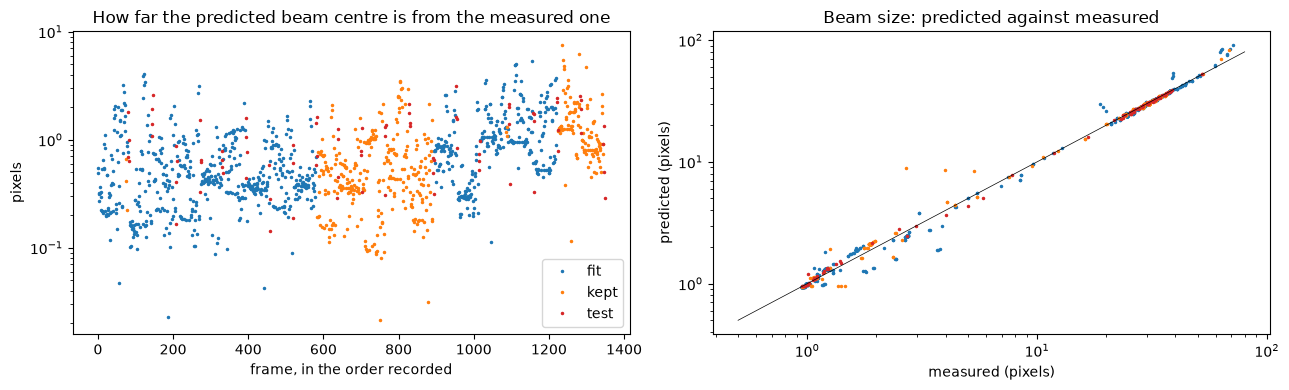

In [8]:
predict = jax.jit(jax.vmap(beam_on_camera, in_axes=(None, 0)))
before = np.asarray(predict({key: jnp.asarray(value) for key, value in best_guess.items()}, dac))
after = np.asarray(predict(fitted, dac))
miss = np.hypot(*(after[:, :2] - measured[:, :2]).T)
size_error = np.abs(np.log(after[:, 2] / measured[:, 2]))

print(f"{'':8s}{'frames':>7s}{'centre, before':>16s}{'centre: rms':>13s}{'median':>8s}{'worst':>7s}{'size: median':>14s}")
for name in ("fit", "kept", "test"):
    m = split == name
    print(f"{name:8s}{m.sum():7d}{np.sqrt((np.hypot(*(before[m, :2] - measured[m, :2]).T) ** 2).mean()):13.1f} px"
          f"{np.sqrt((miss[m] ** 2).mean()):10.2f} px{np.median(miss[m]):8.2f}{miss[m].max():7.1f}"
          f"{100 * np.median(size_error[m]):12.1f} %")
print("\nby row (a frame is 479 pixels wide; kicks moved the beam about 80 pixels):")
for name in dict.fromkeys(rowname):
    m = rowname == name
    print(f"   {name:11s} {'kept' if 'kept' in split[m][:1] else 'fit ':5s} centre rms {np.sqrt((miss[m] ** 2).mean()):5.2f} px, "
          f"worst {miss[m].max():5.1f} px;  size median {100 * np.median(size_error[m]):4.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, colour in (("fit", "C0"), ("kept", "C1"), ("test", "C3")):
    m = split == name
    axes[0].semilogy(np.where(m)[0], miss[m], ".", ms=3, color=colour, label=name)
    axes[1].loglog(measured[m, 2], after[m, 2], ".", ms=3, color=colour, label=name)
axes[0].set(title="How far the predicted beam centre is from the measured one", xlabel="frame, in the order recorded",
            ylabel="pixels")
axes[1].plot([0.5, 80], [0.5, 80], "k", lw=0.5)
axes[1].set(title="Beam size: predicted against measured", xlabel="measured (pixels)", ylabel="predicted (pixels)")
axes[0].legend()
fig.tight_layout()

## 5. Steering: the model turned round

At MAG 60k, a row the fit never saw, ask for the beam at (60, −40) pixels with a size of 25 pixels. The model says
which CLA1 and CL3 give that: Newton's method on the fitted model, with its slopes from `jax.jacfwd`. Then set
them through PyJEM and look.

In [9]:
eos.SelectFunctionMode(0)
eos.SetSelector(MAG["X60k"])
now = ({name: jnp.asarray(float(getattr(lens, "Get" + name)())) for name in LENSES}
       | {name: jnp.asarray(getattr(deflector, "Get" + name)(), float) for name in DEFLECTORS})
wanted = jnp.array([60.0, -40.0 * Y_SIGN, 25.0])
miss_for = lambda v: beam_on_camera(fitted, now | dict(CLA1=v[:2], CL3=v[2])) - wanted
v = jnp.r_[now["CLA1"], now["CL3"]]
for _ in range(8):
    v = v - jnp.linalg.solve(jax.jacfwd(miss_for)(v), miss_for(v))
print("the console now:  CLA1", np.asarray(now["CLA1"]).astype(int), " CL3", int(now["CL3"]))
print("the model asks:   CLA1", np.round(np.asarray(v[:2])).astype(int), " CL3", int(round(float(v[2]))))
deflector.SetCLA1(int(round(float(v[0]))), int(round(float(v[1]))))
set_lens("CL3", round(float(v[2])))
beam = look("MAG X60k", "steered", "steered")
print(f"asked for (60, -40) px, size 25 px;  got ({beam['x']:.1f}, {beam['y']:.1f}) px, size {beam['size']:.1f} px")

the console now:  CLA1 [35095 35452]  CL3 30470
the model asks:   CLA1 [34640 34216]  CL3 29575
asked for (60, -40) px, size 25 px;  got (60.4, -40.7) px, size 25.6 px


## 6. Which frames are needed

The same fit, with parts of the recording left out, scored on the same kept-back and test frames.

In [10]:
is_kick = np.isin(role, ("kick", "trial kick"))
two_rows = np.isin(rowname, ("MAG X8000", "MAG X40k", "MAG X300k", "DIFF 15cm", "DIFF 80cm"))
recipes = {
    "everything": fitted_rows,
    "no lens wobbles": fitted_rows & (role != "wobble"),
    "IS1, IS2 kicks at 5 rows only": fitted_rows & ~(is_kick & np.isin(what, ("IS1", "IS2")) & ~two_rows),
    "every other row": fitted_rows & np.isin(rowname, ("MAG X8000", "MAG X20k", "MAG X40k", "MAG X150k", "MAG X500k",
                                                       "DIFF 8cm", "DIFF 40cm", "DIFF 150cm")),
}
unseen = np.isin(split, ("kept", "test"))
print(f"{'frames fitted':>44s}{'unseen frames: centre rms':>28s}{'median':>8s}{'size median':>13s}")
for name, use in recipes.items():
    best = fits[0] if name == "everything" else fit(use, Y_SIGN)[0][0]
    out = np.asarray(predict(best, dac))
    d = np.hypot(*(out[:, :2] - measured[:, :2]).T)[unseen]
    s = np.abs(np.log(out[:, 2] / measured[:, 2]))[unseen]
    print(f"{name:32s}{int(use.sum()):12d}{np.sqrt((d ** 2).mean()):25.2f} px{np.median(d):8.2f}{100 * np.median(s):11.1f} %")

                               frames fitted   unseen frames: centre rms  median  size median
everything                               854                     1.25 px    0.69        1.3 %


no lens wobbles                          635                    13.17 px    1.23        2.4 %


IS1, IS2 kicks at 5 rows only            761                     1.31 px    0.68        1.4 %


every other row                          499                     2.11 px    1.02        1.6 %


**Reading the table.** Lens wobbles cannot be left out: without them the fit still predicts kicks, but not what a
changed lens does (the test frames go wrong). Kicking IS1 and IS2 at a few rows only, or recording every other row,
costs little. So the session can be about half the size of this rehearsal.

## 7. What this does not pin down: where the lenses are

The best fits, with how well each predicts the unseen frames and where it puts the lenses. A fit can predict the
beam to a pixel or two with its projection lenses centimetres from the hidden ones, and other fits put them tens
of centimetres away while still predicting to a few pixels. One camera cannot tell these columns apart well
(section 5 of `neoarm_model.ipynb`): the positions from this fit are not to be trusted, the predictions are.

In [11]:
true_z = np.asarray(hidden["lens_z"]) / L_HIDDEN
print(f"{'':28s}" + "".join(f"{name:>8s}" for name in LENSES) + "   unseen centre rms")
print(f"{'hidden microscope (z / L)':28s}" + "".join(f"{z:8.3f}" for z in true_z))
for k in range(5):
    out = np.asarray(predict(fits[k], dac))
    d = np.hypot(*(out[:, :2] - measured[:, :2]).T)[unseen]
    print(f"{'fit ' + str(k + 1) + f' (misfit {misfits[k]:.0f})':28s}" + "".join(f"{z:8.3f}" for z in np.asarray(fits[k]["lens_z"]))
          + f"{np.sqrt((d ** 2).mean()):12.2f} px")
print(f"\nIn metres the hidden lenses are at z = L × these, with L = {L_HIDDEN} m: a number no SightX frame contains.")

                                 CL1     CL3      CM     IL1     IL2     IL3     PL1   unseen centre rms
hidden microscope (z / L)     -0.718  -0.610  -0.136   0.288   0.338   0.358   0.413
fit 1 (misfit 18319)          -0.759  -0.573  -0.144   0.223   0.267   0.291   0.359        1.25 px
fit 2 (misfit 22266)          -0.695  -0.597  -0.129   0.308   0.352   0.376   0.444        1.35 px
fit 3 (misfit 48117)          -0.712  -0.586  -0.126   0.242   0.213   0.238   0.306        2.32 px
fit 4 (misfit 158507)         -0.710  -0.597  -0.138   0.414   0.752   0.883   0.963        4.53 px
fit 5 (misfit 160131)         -0.707  -0.598  -0.128   0.518   0.735   0.868   0.947        4.48 px

In metres the hidden lenses are at z = L × these, with L = 0.7 m: a number no SightX frame contains.


## 8. From a predictor to real lens positions and L

Three separate things are missing, and each needs its own measurement:

| Missing | Why frames of the beam cannot give it | What gives it |
|---|---|---|
| **Pixels per length** at the camera | only pixels are seen | the SightX's 1916 pixels are 12 cm wide |
| **L** (and with it every lens position in metres, every deflector in radians) | a longer column with weaker lenses gives the same frames | one known angle at the specimen: **gold diffraction rings**. A ring of angle θ has radius θ × camera length; the model gives the camera length in units of L, the frame gives it in pixels, the pixel size turns pixels into metres: L follows. A **cross-grating image** gives a second, independent check through the magnification. |
| **Where each lens is** inside L | PL1 never changes in the console's rows, so "PL1 stronger and the camera further" gives the same frames (section 7) | frames with **PL1 changed on purpose** (the 8k–20k rows already move PL1 a little; larger steps pin it), or the **second camera** (the Merlin, a known distance below the SightX) |

So the order is: (1) the predictor, as here; (2) the rulers, which give L and the pixel size without changing any
prediction; (3) PL1 steps or the Merlin, which decide between the columns that predict equally well.

## 9. What to take to the microscope

The recording cell above is the recipe. Frame counts from this rehearsal (a real session needs about half: every
other row, and fewer kept-back rows):

In [12]:
counts = {}
for f in frames:
    counts[f["role"]] = counts.get(f["role"], 0) + 1
for name, n in counts.items():
    print(f"{name:16s}{n:6d} frames")
print(f"{'all':16s}{len(frames):6d} frames at {len(PLAN)} rows: about {len(frames) * 5 / 60:.0f} minutes at 5 s a frame, "
      f"{len(frames) * 20 / 3600:.1f} hours at 20 s a frame")

sizing              27 frames
reference          181 frames
trial kick         165 frames
kick               496 frames
wobble             336 frames
CL3 step            42 frames
spot                30 frames
several at once     84 frames
steered              1 frames
all               1362 frames at 21 rows: about 114 minutes at 5 s a frame, 7.6 hours at 20 s a frame
